ПРАКТИЧЕСКАЯ РАБОТА №10
КЛАСТЕРНЫЙ АНАЛИЗ
Файл загружен. Форма: (2000, 8)

Первые 5 строк:
          ID  Sex  Marital status  Age  Education  Income  Occupation  \
0  100000001    0               0   67          2  124670           1   
1  100000002    1               1   22          1  150773           1   
2  100000003    0               0   49          1   89210           0   
3  100000004    0               0   45          1  171565           1   
4  100000005    0               0   53          1  149031           1   

   Settlement size  
0                2  
1                2  
2                0  
3                1  
4                1  

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   ID               2000 non-null   int64
 1   Sex              2000 non-null   int64
 2   Marital status   2000 non-null   in

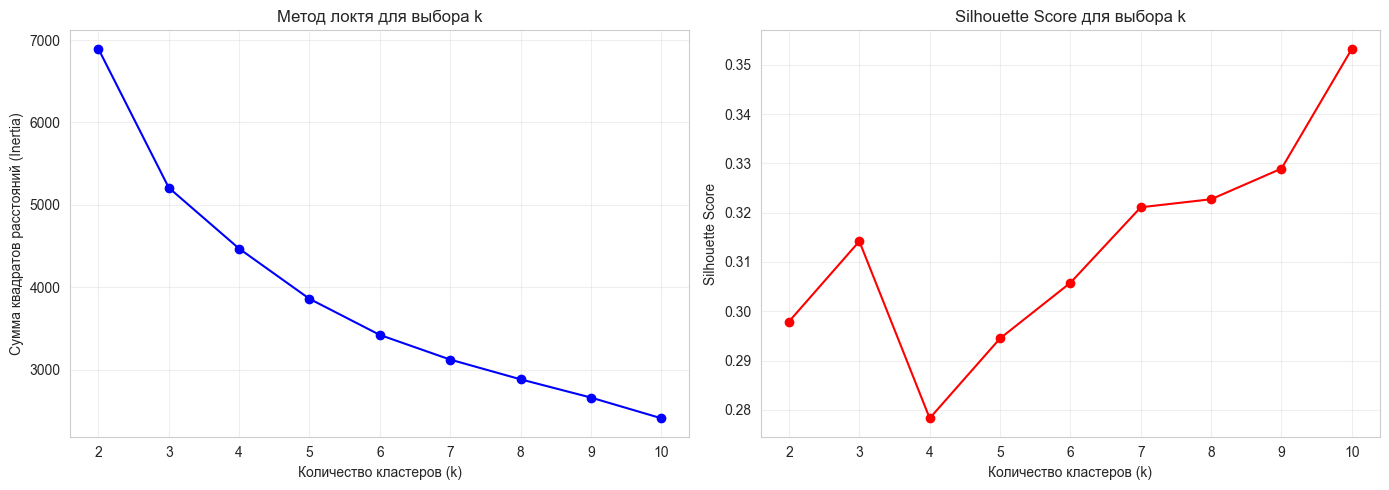


Оптимальное количество кластеров по silhouette score: 10
Silhouette score для k=10: 0.3532

Значения для разных k:
  k=2: Inertia=6892.47, Silhouette=0.2979
  k=3: Inertia=5207.77, Silhouette=0.3142
  k=4: Inertia=4468.83, Silhouette=0.2783
  k=5: Inertia=3859.71, Silhouette=0.2945
  k=6: Inertia=3421.77, Silhouette=0.3058
  k=7: Inertia=3122.62, Silhouette=0.3211
  k=8: Inertia=2883.27, Silhouette=0.3227
  k=9: Inertia=2661.94, Silhouette=0.3289
  k=10: Inertia=2410.88, Silhouette=0.3532

КЛАСТЕРИЗАЦИЯ (k=10)

Распределение по кластерам:
Cluster
0    304
1    140
2    412
3    349
4    153
5    133
6    137
7     80
8    179
9    113
Name: count, dtype: int64

Центры кластеров (в исходных единицах):
             Age     Income  Education  Occupation  Settlement size
Cluster_0  30.93  116382.67       0.99        1.01             0.00
Cluster_1  55.66  143019.07       2.14        0.91             1.24
Cluster_2  32.70   87140.45       1.00        0.00             0.03
Cluster_3  28.84 

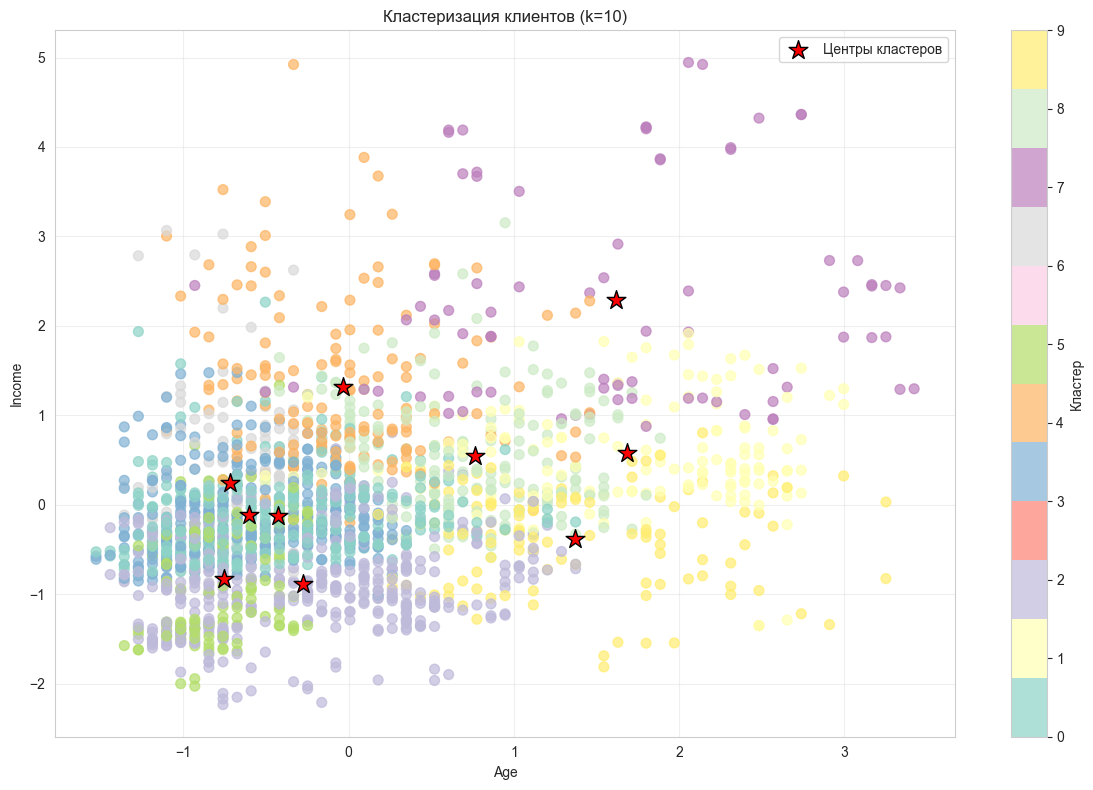


ПРОФИЛИ КЛАСТЕРОВ

Числовые характеристики кластеров:
           Age                   Income                     Education         \
          mean median    std       mean    median       std      mean median   
Cluster                                                                        
0        30.93   30.0   6.80  116382.67  112977.0  17219.61      0.99    1.0   
1        55.66   58.0   9.85  143019.07  138485.5  21453.51      2.14    2.0   
2        32.70   33.0   7.84   87140.45   85994.5  19699.40      1.00    1.0   
3        28.84   28.0   5.30  116507.26  113004.0  17155.25      1.00    1.0   
4        35.52   35.0   6.42  171131.99  161323.0  34376.75      0.91    1.0   
5        27.05   27.0   3.24   89295.89   84531.0  24482.53      0.00    0.0   
6        27.50   27.0   3.29  130196.86  126060.0  30771.21      0.00    0.0   
7        54.85   55.0  11.99  207985.48  197268.0  44652.26      2.10    2.0   
8        44.85   45.0   6.19  141891.02  137069.0  23875.27      

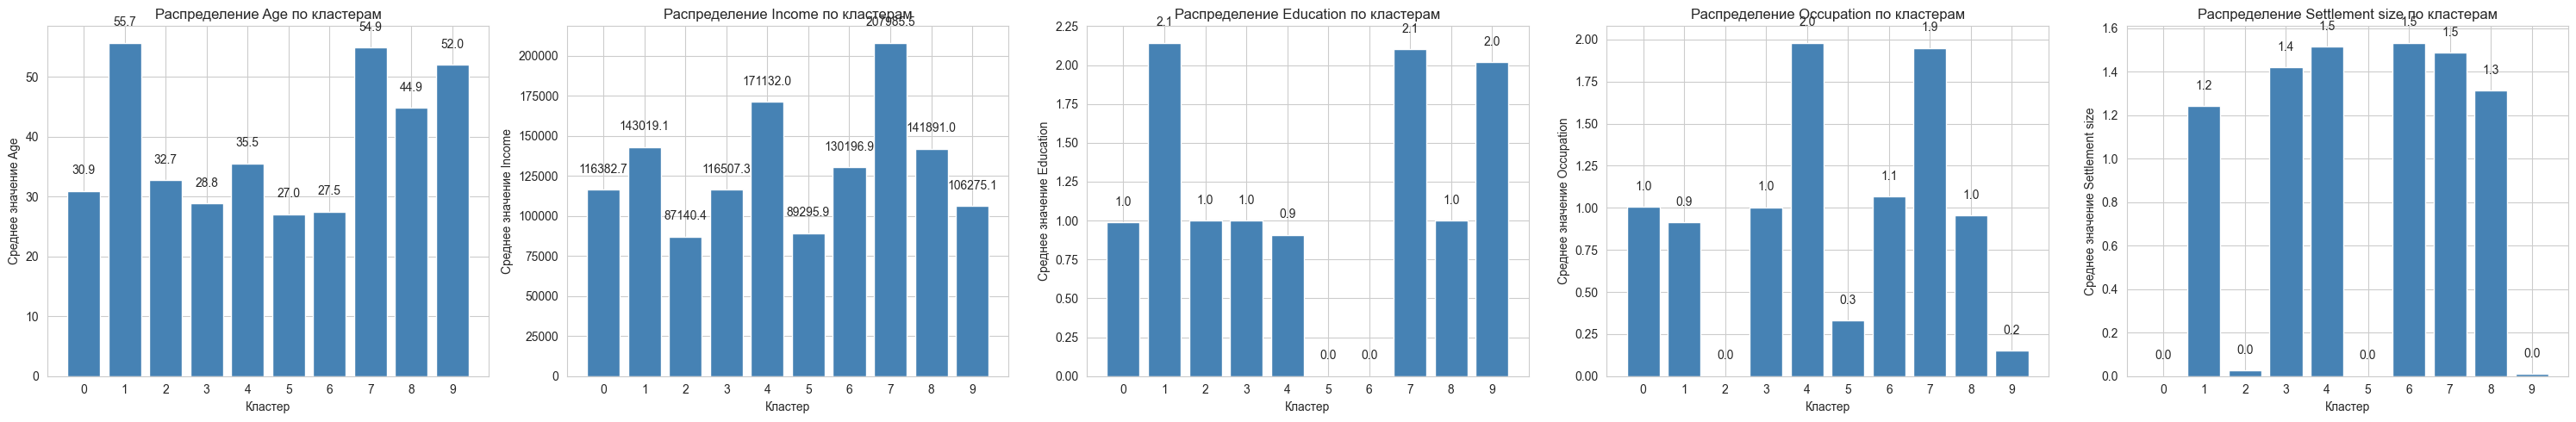

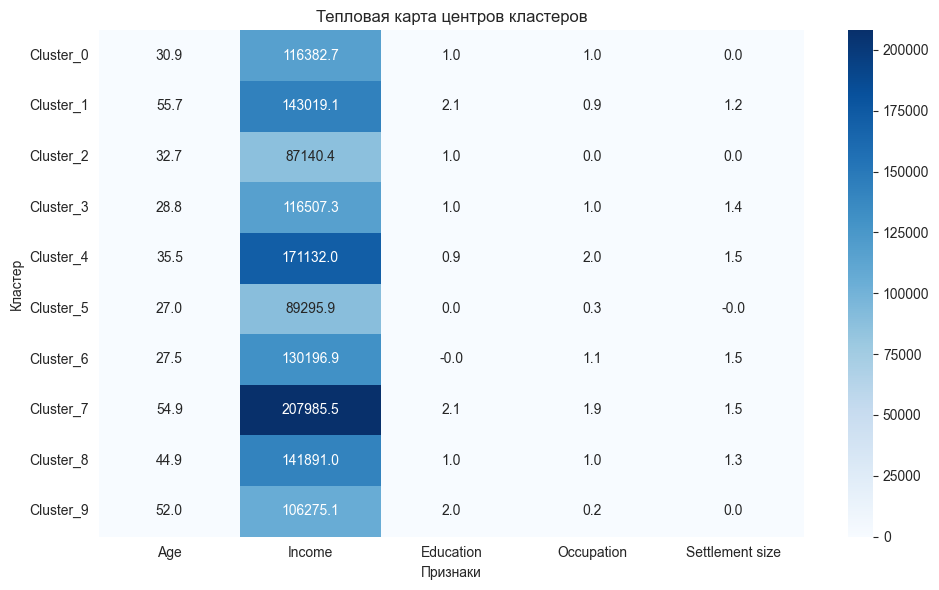


ВЫВОДЫ ПО КЛАСТЕРАМ

КЛАСТЕР 0 (304 клиентов, 15.2% от всех)

ЧИСЛОВЫЕ ХАРАКТЕРИСТИКИ:
  Age: среднее=30.9, медиана=30.0
  Income: среднее=116382.7, медиана=112977.0
  Education: среднее=1.0, медиана=1.0
  Occupation: среднее=1.0, медиана=1.0
  Settlement size: среднее=0.0, медиана=0.0

КАТЕГОРИАЛЬНЫЕ ХАРАКТЕРИСТИКИ:
  Пол: {'Female': np.float64(0.67), 'Male': np.float64(0.33)}
  Семейное положение: {'Married': np.float64(0.67), 'Single': np.float64(0.33)}
  Образование: {'School': np.float64(0.99), 'Uneducated': np.float64(0.01)}
  Занятость: {'Employed': np.float64(0.99), 'Unemployed': np.float64(0.01)}
  Тип поселения: {'Rural': np.float64(1.0)}

ОПИСАНИЕ КЛАСТЕРА:
  Кластер характеризуется: средний доход, средняя возрастная группа, преимущественно female, преимущественно married, проживают в rural районах

КЛАСТЕР 1 (140 клиентов, 7.0% от всех)

ЧИСЛОВЫЕ ХАРАКТЕРИСТИКИ:
  Age: среднее=55.7, медиана=58.0
  Income: среднее=143019.1, медиана=138485.5
  Education: среднее=2.1, медиана

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

print("ПРАКТИЧЕСКАЯ РАБОТА №10")
print("КЛАСТЕРНЫЙ АНАЛИЗ")
print("="*60)

# ============================================================
# 1. ЗАГРУЗКА ДАННЫХ
# ============================================================

DATA_FILE = "data/segmentation_data.csv"

try:
    df = pd.read_csv(DATA_FILE)
    print(f"Файл загружен. Форма: {df.shape}")
    print("\nПервые 5 строк:")
    print(df.head())
except FileNotFoundError:
    print(f"Ошибка: файл '{DATA_FILE}' не найден")
    exit(1)
except Exception as e:
    print(f"Ошибка загрузки: {e}")
    exit(1)

print("\nИнформация о данных:")
df.info()

print("\nОписательная статистика:")
print(df.describe())

# ============================================================
# 2. ОЧИСТКА И ПОДГОТОВКА ДАННЫХ
# ============================================================

print("\n" + "="*60)
print("ОЧИСТКА И ПОДГОТОВКА ДАННЫХ")
print("="*60)

# Проверка пропусков
print("\nПропуски в данных:")
print(df.isnull().sum())

# Удаляем ID (не нужен для кластеризации)
if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

# Описание категорий (по данным из описания датасета)
sex_mapping = {0: 'Male', 1: 'Female'}
marital_mapping = {0: 'Single', 1: 'Married'}
education_mapping = {0: 'Uneducated', 1: 'School', 2: 'College', 3: 'Graduate', 4: 'Post Graduate'}
occupation_mapping = {0: 'Unemployed', 1: 'Employed'}
settlement_mapping = {0: 'Rural', 1: 'Suburban', 2: 'Urban'}

# Создаем копии для интерпретации
df_interpret = df.copy()
df_interpret['Sex_desc'] = df_interpret['Sex'].map(sex_mapping)
df_interpret['Marital_status_desc'] = df_interpret['Marital status'].map(marital_mapping)
df_interpret['Education_desc'] = df_interpret['Education'].map(education_mapping)
df_interpret['Occupation_desc'] = df_interpret['Occupation'].map(occupation_mapping)
df_interpret['Settlement_size_desc'] = df_interpret['Settlement size'].map(settlement_mapping)

print("\nРаспределение категориальных переменных:")
print("\nПол:")
print(df_interpret['Sex_desc'].value_counts())
print("\nСемейное положение:")
print(df_interpret['Marital_status_desc'].value_counts())
print("\nОбразование:")
print(df_interpret['Education_desc'].value_counts())
print("\nЗанятость:")
print(df_interpret['Occupation_desc'].value_counts())
print("\nТип поселения:")
print(df_interpret['Settlement_size_desc'].value_counts())

# ============================================================
# 3. ВЫБОР ПРИЗНАКОВ ДЛЯ КЛАСТЕРИЗАЦИИ
# ============================================================

print("\n" + "="*60)
print("ВЫБОР ПРИЗНАКОВ ДЛЯ КЛАСТЕРИЗАЦИИ")
print("="*60)

# Выбираем числовые признаки для кластеризации
feature_cols = ['Age', 'Income']
if 'Education' in df.columns:
    feature_cols.append('Education')
if 'Occupation' in df.columns:
    feature_cols.append('Occupation')
if 'Settlement size' in df.columns:
    feature_cols.append('Settlement size')

print(f"Признаки для кластеризации: {feature_cols}")

X = df[feature_cols].copy()

# Нормализация данных
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)

print("\nНормализованные данные (первые 5 строк):")
print(X_scaled_df.head())

# ============================================================
# 4. ОПРЕДЕЛЕНИЕ ОПТИМАЛЬНОГО КОЛИЧЕСТВА КЛАСТЕРОВ
# ============================================================

print("\n" + "="*60)
print("ОПРЕДЕЛЕНИЕ ОПТИМАЛЬНОГО КОЛИЧЕСТВА КЛАСТЕРОВ")
print("="*60)

# Метод локтя (Elbow Method)
inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Визуализация метода локтя
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias, 'bo-')
axes[0].set_xlabel('Количество кластеров (k)')
axes[0].set_ylabel('Сумма квадратов расстояний (Inertia)')
axes[0].set_title('Метод локтя для выбора k')
axes[0].grid(True, alpha=0.3)

axes[1].plot(K_range, silhouette_scores, 'ro-')
axes[1].set_xlabel('Количество кластеров (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score для выбора k')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Выбираем оптимальное k (по методу локтя и silhouette score)
best_k = K_range[np.argmax(silhouette_scores)]
print(f"\nОптимальное количество кластеров по silhouette score: {best_k}")
print(f"Silhouette score для k={best_k}: {silhouette_scores[best_k-2]:.4f}")

# Также выводим значения для всех k
print("\nЗначения для разных k:")
for k, inert, sil in zip(K_range, inertias, silhouette_scores):
    print(f"  k={k}: Inertia={inert:.2f}, Silhouette={sil:.4f}")

# ============================================================
# 5. КЛАСТЕРИЗАЦИЯ
# ============================================================

print("\n" + "="*60)
print(f"КЛАСТЕРИЗАЦИЯ (k={best_k})")
print("="*60)

# Выполняем кластеризацию с оптимальным k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# Добавляем метки кластеров в датафреймы
df['Cluster'] = kmeans.labels_
df_interpret['Cluster'] = kmeans.labels_
X_scaled_df['Cluster'] = kmeans.labels_

print(f"\nРаспределение по кластерам:")
print(df['Cluster'].value_counts().sort_index())

# Центры кластеров в исходном масштабе
cluster_centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
cluster_centers_df = pd.DataFrame(cluster_centers_original,
                                  columns=feature_cols,
                                  index=[f'Cluster_{i}' for i in range(best_k)])
print("\nЦентры кластеров (в исходных единицах):")
print(cluster_centers_df.round(2))

# ============================================================
# 6. ВИЗУАЛИЗАЦИЯ КЛАСТЕРОВ
# ============================================================

print("\n" + "="*60)
print("ВИЗУАЛИЗАЦИЯ КЛАСТЕРОВ")
print("="*60)

# 2D визуализация (по первым двум признакам)
plt.figure(figsize=(12, 8))

# Scatter plot с цветами кластеров
scatter = plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
                      c=kmeans.labels_, cmap='Set3', s=50, alpha=0.7)

# Отмечаем центры кластеров
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            s=200, c='red', marker='*', edgecolors='black',
            label='Центры кластеров', zorder=5)

plt.xlabel(feature_cols[0])
plt.ylabel(feature_cols[1])
plt.title(f'Кластеризация клиентов (k={best_k})')
plt.colorbar(scatter, label='Кластер')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Pairplot для визуализации всех признаков
if len(feature_cols) >= 2:
    plot_df = X_scaled_df.copy()
    plot_df['Cluster'] = plot_df['Cluster'].astype('category')

    # Создаем pairplot только если колонок не слишком много
    if len(feature_cols) <= 4:
        g = sns.pairplot(plot_df, hue='Cluster', palette='Set3', diag_kind='kde')
        g.fig.suptitle('Pairplot признаков по кластерам', y=1.02)
        plt.show()

# ============================================================
# 7. ПРОФИЛИ КЛАСТЕРОВ
# ============================================================

print("\n" + "="*60)
print("ПРОФИЛИ КЛАСТЕРОВ")
print("="*60)

# Агрегируем данные по кластерам
cluster_profile = df.groupby('Cluster')[feature_cols].agg(['mean', 'median', 'std']).round(2)
print("\nЧисловые характеристики кластеров:")
print(cluster_profile)

# Профиль по категориальным переменным
print("\nКатегориальные характеристики кластеров:")
for cluster in sorted(df['Cluster'].unique()):
    print(f"\n{'='*40}")
    print(f"Кластер {cluster} (размер: {len(df[df['Cluster']==cluster])} клиентов)")
    print(f"{'='*40}")

    cluster_data = df_interpret[df_interpret['Cluster'] == cluster]

    print(f"\nПол:")
    print(cluster_data['Sex_desc'].value_counts(normalize=True).round(2))

    print(f"\nСемейное положение:")
    print(cluster_data['Marital_status_desc'].value_counts(normalize=True).round(2))

    print(f"\nОбразование:")
    print(cluster_data['Education_desc'].value_counts(normalize=True).round(2))

    print(f"\nЗанятость:")
    print(cluster_data['Occupation_desc'].value_counts(normalize=True).round(2))

    print(f"\nТип поселения:")
    print(cluster_data['Settlement_size_desc'].value_counts(normalize=True).round(2))

# ============================================================
# 8. ВИЗУАЛИЗАЦИЯ ПРОФИЛЕЙ КЛАСТЕРОВ
# ============================================================

print("\n" + "="*60)
print("ВИЗУАЛИЗАЦИЯ ПРОФИЛЕЙ КЛАСТЕРОВ")
print("="*60)

# Графики средних значений по кластерам
fig, axes = plt.subplots(1, len(feature_cols), figsize=(6*len(feature_cols), 5))

if len(feature_cols) == 1:
    axes = [axes]

for i, col in enumerate(feature_cols):
    means = df.groupby('Cluster')[col].mean()
    axes[i].bar(means.index, means.values, color='steelblue')
    axes[i].set_xlabel('Кластер')
    axes[i].set_ylabel(f'Среднее значение {col}')
    axes[i].set_title(f'Распределение {col} по кластерам')
    axes[i].set_xticks(means.index)
    for j, v in enumerate(means.values):
        axes[i].text(j, v + 0.05 * max(means.values), f'{v:.1f}', ha='center')

plt.tight_layout()
plt.show()

# Тепловая карта центров кластеров
plt.figure(figsize=(10, 6))
sns.heatmap(cluster_centers_df, annot=True, cmap='Blues', fmt='.1f')
plt.title('Тепловая карта центров кластеров')
plt.xlabel('Признаки')
plt.ylabel('Кластер')
plt.tight_layout()
plt.show()

# ============================================================
# 9. ВЫВОДЫ ПО КЛАСТЕРАМ
# ============================================================

print("\n" + "="*60)
print("ВЫВОДЫ ПО КЛАСТЕРАМ")
print("="*60)

# Сортируем кластеры по размеру
cluster_sizes = df['Cluster'].value_counts().sort_index()

for cluster in sorted(df['Cluster'].unique()):
    size = cluster_sizes[cluster]
    percent = size / len(df) * 100

    print(f"\n{'='*50}")
    print(f"КЛАСТЕР {cluster} ({size} клиентов, {percent:.1f}% от всех)")
    print(f"{'='*50}")

    # Числовые характеристики
    print("\nЧИСЛОВЫЕ ХАРАКТЕРИСТИКИ:")
    cluster_data_num = df[df['Cluster'] == cluster]
    for col in feature_cols:
        mean_val = cluster_data_num[col].mean()
        median_val = cluster_data_num[col].median()
        print(f"  {col}: среднее={mean_val:.1f}, медиана={median_val:.1f}")

    # Категориальные характеристики
    print("\nКАТЕГОРИАЛЬНЫЕ ХАРАКТЕРИСТИКИ:")
    cluster_data_cat = df_interpret[df_interpret['Cluster'] == cluster]

    # Пол
    sex_dist = cluster_data_cat['Sex_desc'].value_counts(normalize=True)
    print(f"  Пол: {dict(sex_dist.round(2))}")

    # Семейное положение
    marital_dist = cluster_data_cat['Marital_status_desc'].value_counts(normalize=True)
    print(f"  Семейное положение: {dict(marital_dist.round(2))}")

    # Образование
    edu_dist = cluster_data_cat['Education_desc'].value_counts(normalize=True)
    print(f"  Образование: {dict(edu_dist.round(2))}")

    # Занятость
    occ_dist = cluster_data_cat['Occupation_desc'].value_counts(normalize=True)
    print(f"  Занятость: {dict(occ_dist.round(2))}")

    # Тип поселения
    sett_dist = cluster_data_cat['Settlement_size_desc'].value_counts(normalize=True)
    print(f"  Тип поселения: {dict(sett_dist.round(2))}")

    # Описание кластера
    print("\nОПИСАНИЕ КЛАСТЕРА:")

    # Формируем описание на основе признаков
    desc_parts = []

    # Доход
    income_mean = cluster_data_num['Income'].mean()
    overall_income_mean = df['Income'].mean()
    if income_mean > overall_income_mean * 1.2:
        desc_parts.append("высокий доход")
    elif income_mean < overall_income_mean * 0.8:
        desc_parts.append("низкий доход")
    else:
        desc_parts.append("средний доход")

    # Возраст
    age_mean = cluster_data_num['Age'].mean()
    overall_age_mean = df['Age'].mean()
    if age_mean > overall_age_mean * 1.2:
        desc_parts.append("старшая возрастная группа")
    elif age_mean < overall_age_mean * 0.8:
        desc_parts.append("младшая возрастная группа")
    else:
        desc_parts.append("средняя возрастная группа")

    # Основной пол
    main_sex = sex_dist.idxmax() if len(sex_dist) > 0 else "смешанный"
    if main_sex != "смешанный" and sex_dist[main_sex] > 0.6:
        desc_parts.append(f"преимущественно {main_sex.lower()}")

    # Основное семейное положение
    main_marital = marital_dist.idxmax() if len(marital_dist) > 0 else "различное"
    if main_marital != "различное" and marital_dist[main_marital] > 0.6:
        desc_parts.append(f"преимущественно {main_marital.lower()}")

    # Основной тип поселения
    main_sett = sett_dist.idxmax() if len(sett_dist) > 0 else "различный"
    if main_sett != "различный" and sett_dist[main_sett] > 0.6:
        desc_parts.append(f"проживают в {main_sett.lower()} районах")

    print(f"  Кластер характеризуется: {', '.join(desc_parts)}")

print("\n" + "="*60)
print("ИТОГОВЫЕ ВЫВОДЫ")
print("="*60)

print(f"\n1. Оптимальное количество кластеров: {best_k}")
print(f"2. Silhouette score: {silhouette_scores[best_k-2]:.4f}")
print("3. Кластеры различаются по возрастным группам, уровню дохода,")
print("   семейному положению и типу поселения.")
print("4. Полученные кластеры могут быть использованы для:")
print("   - таргетированной рекламы")
print("   - персонализации предложений")
print("   - анализа потребительского поведения")

print("\n" + "="*60)